In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import glob

In [33]:
import matplotlib.pyplot as plt

def plot_loss(ax, data, fold, unfreeze_epochs, baseline=None):

    train = data["train_losses"]
    val = data["val_losses"]
    IoUs = data["val_ious"]
    F1s = data["val_f1s"]

    x = range(1, len(train) + 1)

    ax.plot(x, train, label="train")
    ax.plot(x, val, label="val")
    #ax.plot(x, IoUs, label="IoU")
    #ax.plot(x, F1s, label="F1")

    baseline = val[20] if baseline is None else baseline

    for e in unfreeze_epochs:
        ax.axvline(e - 0.5, color="grey", ls="--", lw=0.8)
        
    ax.axhline(baseline, color="C1", ls="--", lw=0.8, label="epoch 20 baseline")

    best = min(range(len(val)), key=val.__getitem__)
    ax.scatter(best + 1, val[best], color="C1", zorder=3)

    ax.set_title(f"{fold}")
    ax.set_xlabel("epoch")
    ax.set_ylabel("loss")
    ax.legend()
    return ax



dict_keys(['train_losses', 'val_losses', 'val_recalls', 'val_precisions', 'val_ious', 'val_f1s'])


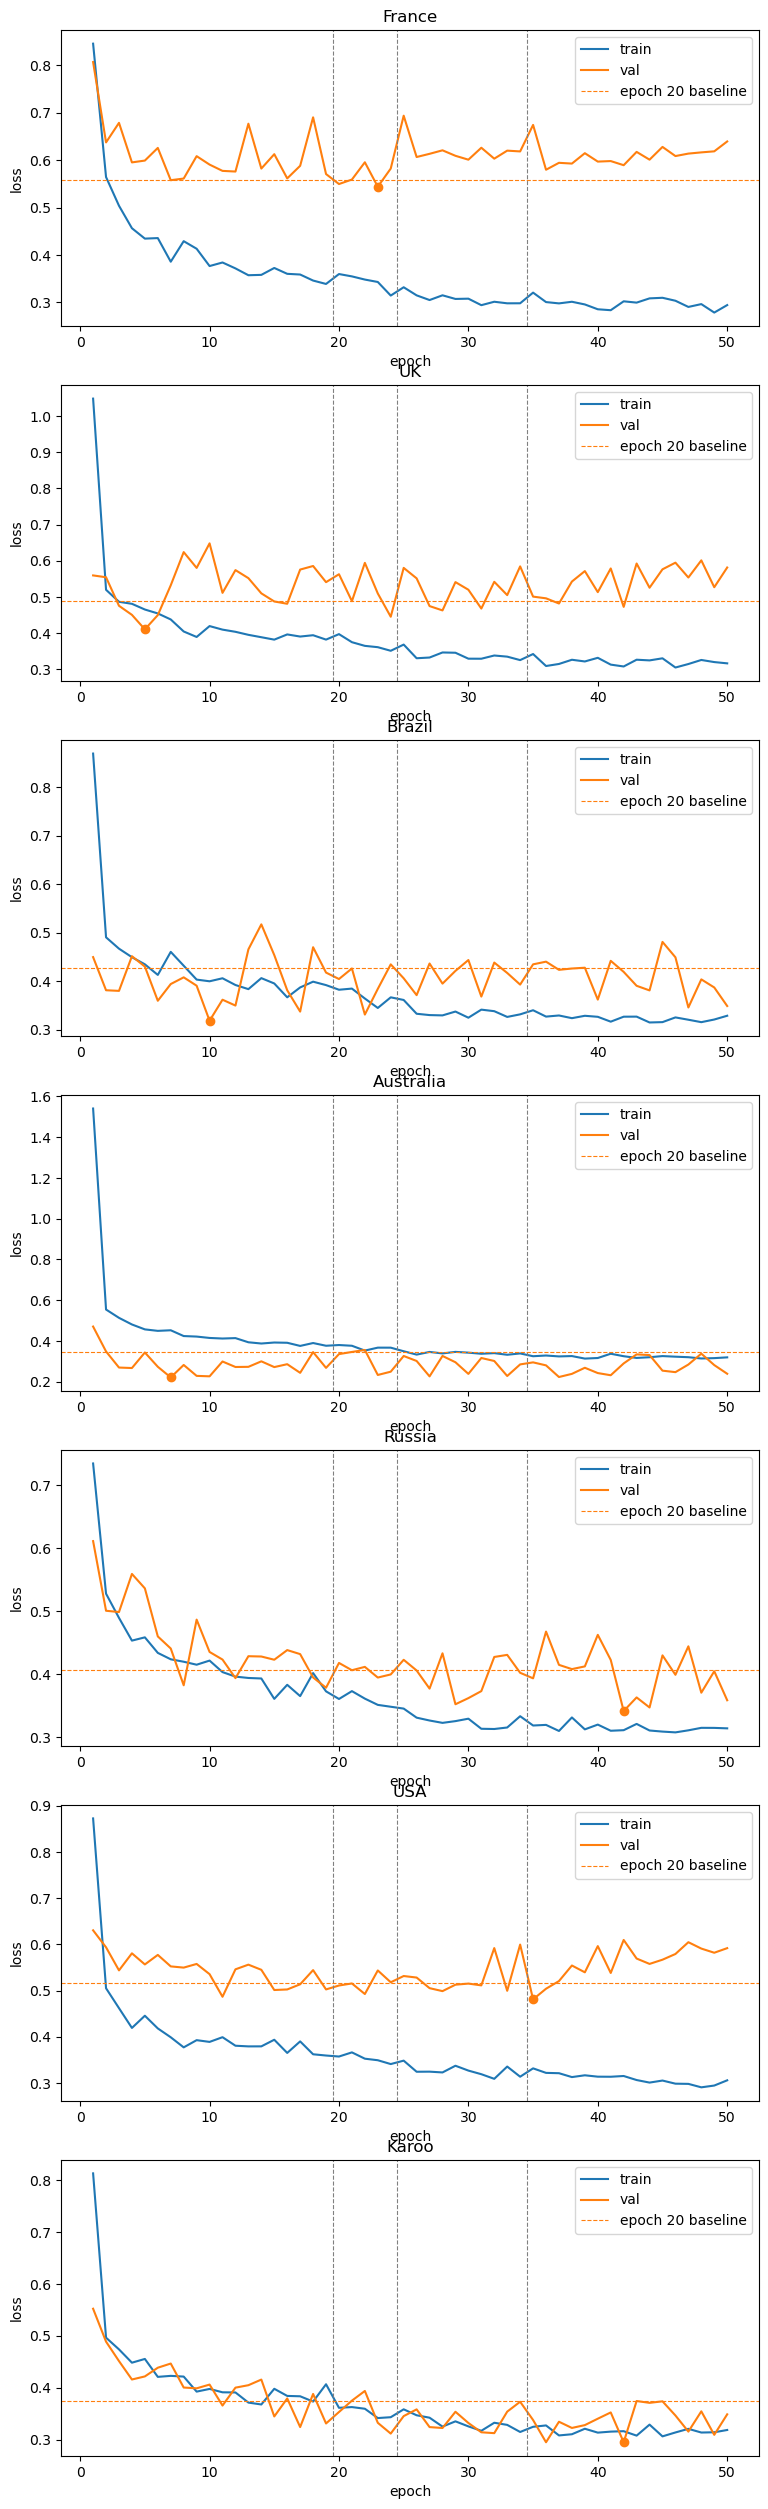

In [34]:
results = np.load('../../data/PostIRP/LORO_CV_results.npz', allow_pickle=True)

fold_n = len(results)
print(results['France'].item().keys())
fig, axes = plt.subplots(fold_n, 1, figsize=(9, 4.5 * fold_n))

for i, (fold, data) in enumerate(results.items()):
    plot_loss(axes[i], data.item(), fold, unfreeze_epochs=[20, 25, 35])